In [1]:
# Libraries:
import numpy as np
import matplotlib.pyplot as plt
import dill
import sys
import os

import pysindy as ps
import D_CODE

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..'))) 
from data import SINDy_data
from data import data
from data import equations

from toolbox.auxiliary_functions import set_param_freq

# Seed:
np.random.seed(999)

/home/mattg/miniforge3/envs/SimbSINDy_env/lib/python3.11/site-packages/pysindy/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound


#### Case $n$, $k$, $k_a$ and $k_y$ fixed
Consider the modified Van der Pol system with a nonlinear forcing term
$$
\begin{cases}
\dot{x} = \frac{k y^n}{k_a + y^n} \\
\dot{y} = - k_y y
\end{cases}
$$
and with $n=2.8$, $k=1$, $k_a=4$ and $k_y=0.1$ fixed.

In [2]:
# Select ODE & settings:
ode_name = 'HillODE' # help="name of the ode", type=str
ode_param = '2.8,1,4,0.1' # help="parameters of the ode (default: None)", type=str, default=None
freq = 10 # help="sampling frequency", type=float, default=10
n_sample = 50 # help="number of trajectories", type=int, default=100
noise_ratio = 0.01 # help="noise level (default 0)", type=float, default=0.
seed = 100 # help="random seed", type=int, default=0
n_seed = 1 # help="random seed", type=int, default=10

ode_param, freq = set_param_freq(ode_param, freq)

ode = equations.get_ode(ode_name, ode_param)
dt = 1 / freq
dim_x = 2
dim_k = 0
time_vector = np.arange(0, ode.T + dt, dt)
T = ode.T

In [3]:
# # Generate data:
# X_list, dX_list, param_list, feature_names = SINDy_data.SINDy_data(ode_name, ode_param, freq, n_sample, noise_ratio, dim_x, dim_k)
# print(np.shape(X_list), np.shape(dX_list), np.shape(param_list))
# print(feature_names)

# # Save data:
# file_path = 'saved/data/hillODE_data.pkl'
# os.makedirs(os.path.dirname(file_path), exist_ok=True)
# with open(file_path, 'wb') as f:
#     dill.dump((X_list, dX_list, param_list, feature_names), f)

In [4]:
# Uploda data:
file_path = 'saved/data/hillODE_data.pkl'
with open(file_path, 'rb') as f:
    X_list, dX_list, param_list, feature_names = dill.load(f)

print(np.shape(X_list), np.shape(dX_list), np.shape(param_list))
print(feature_names)

(50, 150, 2) (50, 150, 2) (0,)
['X0', 'X1']


Threshold:  0.01 , RMSE:  0.14272065663620478
Threshold:  0.03 , RMSE:  0.14272065663620478
Threshold:  0.05 , RMSE:  0.5385633770794113
Threshold:  0.08 , RMSE:  0.5755429470996966


/home/mattg/miniforge3/envs/SimbSINDy_env/lib/python3.11/site-packages/pysindy/optimizers/stlsq.py:201: UserWarning: Sparsity parameter is too big (0.1) and eliminated all coefficients
  warnings.warn(


Threshold:  0.1 , RMSE:  2.842376605710561


/home/mattg/miniforge3/envs/SimbSINDy_env/lib/python3.11/site-packages/pysindy/optimizers/stlsq.py:201: UserWarning: Sparsity parameter is too big (0.2) and eliminated all coefficients
  warnings.warn(
/home/mattg/miniforge3/envs/SimbSINDy_env/lib/python3.11/site-packages/pysindy/optimizers/stlsq.py:191: UserWarning: Sparsity parameter is too big (0.2) and eliminated all coefficients
  warnings.warn(


Threshold:  0.2 , RMSE:  4.136898877152138


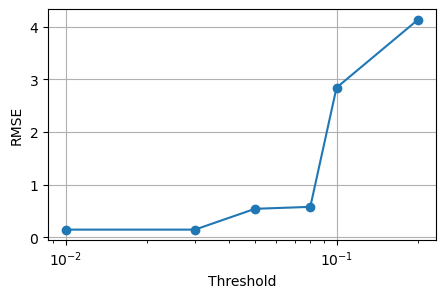

In [5]:
# Model selection:
thresholds = np.array([0.01, 0.03, 0.05, 0.08, 0.1, 0.2])
rmse_values = np.zeros(len(thresholds))
for i in range(len(thresholds)):
    model = ps.SINDy(feature_names=feature_names, feature_library=ps.PolynomialLibrary(degree=3, include_bias=True), optimizer=ps.STLSQ(threshold=thresholds[i]))
    model.fit(X_list, t=dt, multiple_trajectories=True, x_dot=dX_list)
    rmse, _ = SINDy_data.evaluate_RMSE(model, ode, freq, n_sample, [10., 10.], [0., 0.], dim_k)
    rmse_values[i] = rmse
    print('Threshold: ', thresholds[i], ', RMSE: ', rmse)  

plt.figure(figsize=(5, 3))
plt.plot(thresholds, rmse_values, marker='o')
plt.xlabel('Threshold')
plt.ylabel('RMSE')
plt.xscale('log')
plt.grid(True)
plt.show()

In [6]:
# Best model fit
model = ps.SINDy(feature_names=feature_names, feature_library=ps.PolynomialLibrary(degree=3, include_bias=True), optimizer=ps.STLSQ(threshold=0.03))
model.fit(X_list, t=dt, multiple_trajectories=True, x_dot=dX_list)
print("Estimated SINDy model: ")
model.print()

Estimated SINDy model: 
(X0)' = -0.052 1 + 0.375 X1 + -0.032 X1^2
(X1)' = -0.100 X1


##### Plot per report

In [7]:
from report import evaluate_traj

In [8]:
# Evaluate RSME on 10 test trajectories
n_test = 10
rmse, _ = SINDy_data.evaluate_RMSE(model, ode, freq, n_test, [10., 10.], [0., 0.], dim_k)
print('SINDy Model RMSE: ', rmse)

SINDy Model RMSE:  0.20564126900008645


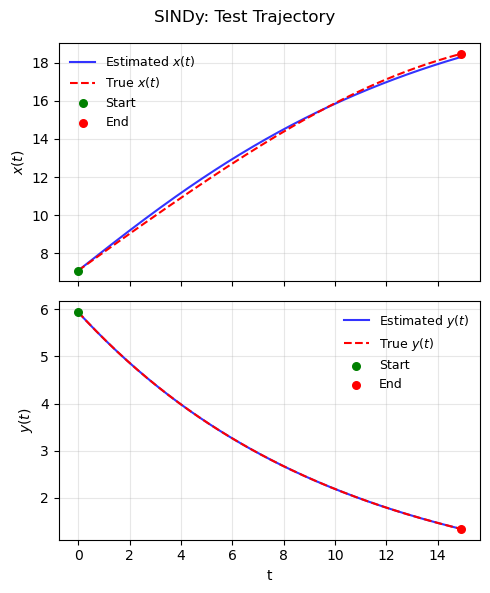

In [9]:
# Simulate a test trajectory starting from an initial condition within the training interval
evaluate_sample = 1
ics = [7., 6.]
title = 'SINDy: Test Trajectory'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=15)

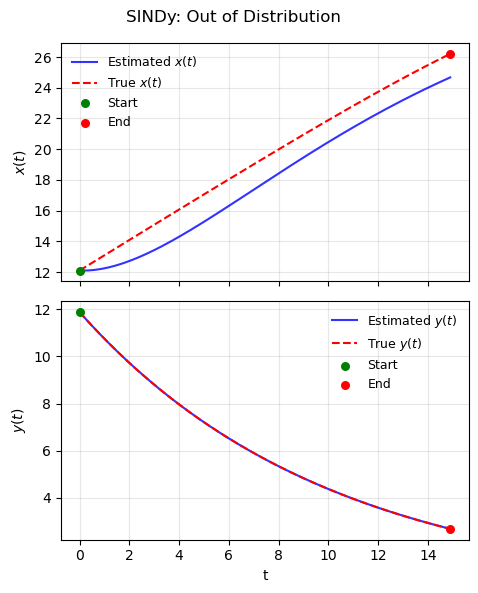

In [ ]:
# Simulate a test trajectory starting from an initial condition outside the training interval
evaluate_sample = 1
ics = [12, 12]
title = 'SINDy: Out of Distribution'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=15)

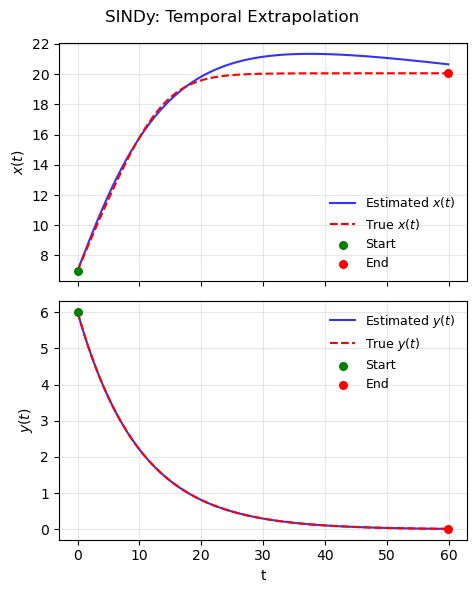

In [ ]:
# Simulate a test trajectory starting from an initial condition within the training interval 
# but with focus on a longer extrapolation time
evaluate_sample = 1
ics = [7, 6]
title = 'SINDy: Temporal Extrapolation'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=60)